<a href="https://colab.research.google.com/github/tanvirrahman0111/Simulation_and_Modeling_Lab_CSE_413/blob/main/Cricket_Simulation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Cricket Match Outcome Simulation and Statistical Validation
**Course:** CSE 413 Simulation and Modeling Lab

**Idea:** T20 match ball-by-ball Monte Carlo simulation, then statistical tests (Chi-square, t-test, KS test) diye model validate kora.

**Ei version e ki ki notun:**
1. **Extras add kora hoise:** Wide (`Wd`), No-ball (`Nb`), Bye (`B`), Leg-bye (`LB`). Wide ar No-ball e *over er ball count hoy na* (extra delivery khelte hoy), Bye/Leg-bye e hoy.
2. Ball outcome ekhon: `0, 1, 2, 3, 4, 5, 6, W, Wd, Nb, B, LB` (12 ta).
3. **CSV / ZIP upload option** add kora hoise (Section 2). Cricsheet er real ball-by-ball data upload korle probability gula **real data theke** estimate hobe. Upload na korle assumed probability diye cholbe.
4. **Real data validation** (Section 9): data ke train/test e bhag kore, train theke model banano, test match er sathe simulation compare kora.

| Class topic | Ekhane kothay use hoise |
|---|---|
| Random number / distribution (Day 3) | ball outcome sampling (inverse-CDF), seed |
| Matrix + plot + heatmap (Day 2) | probability matrix, win-probability heatmap |
| Monte Carlo (Day 4) | 10,000 match, convergence graph |
| Chi-square GOF (Day 6) | simulated outcome vs expected probability, model vs real test data |
| Two-sample t-test (Day 6) | Team A vs Team B average score, simulated vs real score |
| KS / normality test | score distribution normal kina, distribution same kina |

In [ ]:
import io, json, zipfile
from bisect import bisect_left
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)   # reproducible result (Day 3: with seed)

## 1. Model Setup
**Ball outcome (12 ta):**

| Outcome | Mane | Run | Over er ball count hoy? |
|---|---|---|---|
| `0,1,2,3,4,5,6` | bat theke run | 0-6 | Hoy |
| `W` | Wicket | 0 | Hoy |
| `Wd` | Wide | 1 (default) | **Hoy na** |
| `Nb` | No-ball | 1 (default) | **Hoy na** |
| `B` | Bye | 1 (default) | Hoy |
| `LB` | Leg-bye | 1 (default) | Hoy |

Innings: 20 over = 120 *legal* ball, 10 wicket. Wide/No-ball hole extra delivery khelte hoy, tai ekta innings e total delivery 120 er beshi hoy (real cricket er moto).

Probability 3 ta phase e alada: **Powerplay (over 1-6)**, **Middle (7-15)**, **Death (16-20)**.

In [ ]:
OUTCOMES = ['0', '1', '2', '3', '4', '5', '6', 'W', 'Wd', 'Nb', 'B', 'LB']
K   = len(OUTCOMES)
IDX = {o: i for i, o in enumerate(OUTCOMES)}
PHASES = ['Powerplay', 'Middle', 'Death']

# Wide ar No-ball e legal ball count hoy na
LEGAL = np.array([o not in ('Wd', 'Nb') for o in OUTCOMES])

# Run value of each outcome (W = 0). Extras er run default 1; real data dile update hobe.
RUNS = np.array([0, 1, 2, 3, 4, 5, 6, 0, 1, 1, 1, 1])

# ---------- Assumed probabilities (fallback, jodi CSV upload na kori) ----------
# Bat theke outcome (0,1,2,3,4,5,6,W): each row sum = 1
BAT = np.array([
    [0.30, 0.329, 0.07, 0.01, 0.14, 0.001, 0.07, 0.08],   # Powerplay
    [0.30, 0.379, 0.08, 0.01, 0.09, 0.001, 0.05, 0.09],   # Middle
    [0.25, 0.299, 0.08, 0.01, 0.14, 0.001, 0.12, 0.10],   # Death
])
# Extras (Wd, Nb, B, LB) er assumed probability per delivery
EXTRA = np.array([
    [0.045, 0.006, 0.004, 0.012],   # Powerplay
    [0.040, 0.005, 0.004, 0.012],   # Middle
    [0.060, 0.010, 0.004, 0.012],   # Death
])
ASSUMED_PROBS = np.hstack([BAT * (1 - EXTRA.sum(axis=1, keepdims=True)), EXTRA])
print('Row sums:', ASSUMED_PROBS.sum(axis=1))   # must be [1. 1. 1.]

Row sums: [1. 1. 1.]


## 2. Data Load (CSV / JSON / ZIP upload) — optional
**Kibhabe use korbe:**
1. [cricsheet.org/downloads](https://cricsheet.org/downloads/) theke BPL (ba onno kono T20 competition) er **CSV** ba **JSON** zip download koro. Duita format i support kore.
2. `USE_REAL_DATA = True` rekhe cell ta run koro. **Google Colab** e file select korar button ashbe — zip file ta (ba ekta CSV/JSON) upload koro. Zip er bhetor kar `*_info.csv` file auto skip hoy.
3. Local Jupyter e cholale `CSV_PATH = 'bpl_json.zip'` ba `'bpl_csv2.zip'` evabe path dao.
4. Upload na korte chaile `USE_REAL_DATA = False` koro, ba Colab er file dialog e Cancel dao — assumed probability diye cholbe.

**CSV te expected column** (Cricsheet CSV2 format; JSON hole auto convert hoy): `match_id, innings, ball, runs_off_bat, extras, wides, noballs, byes, legbyes, wicket_type`.

In [ ]:
USE_REAL_DATA = True        # False dile assumed probability use hobe
CSV_PATH      = None        # Local run: 'bpl_csv2.zip' ba 'matches.csv'/'bpl_json.zip'. Colab e None rakho (upload button ashbe)

# ---------- 1. ekta file porar function ----------
def read_json_match(raw, name):
    # Cricsheet JSON -> CSV er moto table (ek delivery = ek row)
    match = json.loads(raw)
    rows = []
    for inn_no, inn in enumerate(match.get('innings', []), start=1):
        if inn.get('super_over'):
            continue                                       # super over bad
        for over in inn.get('overs', []):
            for d in over.get('deliveries', []):
                extras  = d.get('extras', {})
                wickets = d.get('wickets', [])
                rows.append({
                    'match_id': name, 'innings': inn_no, 'ball': over.get('over', 0),
                    'runs_off_bat': d.get('runs', {}).get('batter', 0),
                    'extras': d.get('runs', {}).get('extras', 0),
                    'wides': extras.get('wides', 0), 'noballs': extras.get('noballs', 0),
                    'byes': extras.get('byes', 0),   'legbyes': extras.get('legbyes', 0),
                    'wicket_type': wickets[0].get('kind', '') if wickets else ''})
    return pd.DataFrame(rows) if rows else None

def read_file(raw, name):
    # .json ba .csv file porbe; onno file / *_info.csv hole None
    name = name.lower()
    try:
        if name.endswith('.json'):
            return read_json_match(raw, name)
        if name.endswith('.csv') and not name.endswith('_info.csv'):
            df = pd.read_csv(io.BytesIO(raw), low_memory=False)
            if 'innings' not in df.columns or 'ball' not in df.columns:
                return None
            if 'match_id' not in df.columns:
                df['match_id'] = name                      # match id nai hole file name
            return df
    except Exception:
        pass
    return None

def load_files(files):
    # files = {name: bytes}. CSV, JSON ba ZIP (bhetore CSV/JSON) shobi cholbe
    tables = []
    for name, raw in files.items():
        if name.lower().endswith('.zip'):
            z = zipfile.ZipFile(io.BytesIO(raw))
            for inner in z.namelist():
                tables.append(read_file(z.read(inner), inner))
        else:
            tables.append(read_file(raw, name))
    tables = [t for t in tables if t is not None]
    if not tables:
        raise ValueError('Kono valid ball-by-ball file paoa jai nai (Cricsheet CSV ba JSON lagbe).')
    return pd.concat(tables, ignore_index=True)

# ---------- 2. prottek delivery ke ekta outcome (cat) + phase dewa ----------
def get_category(row):
    if row['wides'] > 0:   return 'Wd'
    if row['noballs'] > 0: return 'Nb'
    wk = str(row['wicket_type']).strip().lower()
    if wk not in ('', 'nan', 'retired hurt', 'retired not out'):  return 'W'
    if row['byes'] > 0:    return 'B'
    if row['legbyes'] > 0: return 'LB'
    return str(int(min(max(row['runs_off_bat'], 0), 6)))          # 0..6 run

def prepare(df):
    df = df[df['innings'].isin([1, 2])].copy()                    # super over bad
    df['match_id'] = df['match_id'].astype(str)
    for c in ['runs_off_bat', 'extras', 'wides', 'noballs', 'byes', 'legbyes']:
        if c not in df.columns: df[c] = 0
        df[c] = pd.to_numeric(df[c], errors='coerce').fillna(0)
    if 'wicket_type' not in df.columns: df['wicket_type'] = ''

    df['cat']   = df.apply(get_category, axis=1)
    df['total'] = df['runs_off_bat'] + df['extras']
    over = pd.to_numeric(df['ball'], errors='coerce').fillna(0).astype(int)   # over number (0..19)
    df['phase'] = 0                                                # Powerplay (over 1-6)
    df.loc[over >= 6,  'phase'] = 1                                # Middle    (over 7-15)
    df.loc[over >= 15, 'phase'] = 2                                # Death     (over 16-20)
    return df[df['cat'].isin(OUTCOMES)]

# ---------------- main ----------------
PHASE_PROBS = ASSUMED_PROBS.copy()
REAL_LOADED = False
DATA_SOURCE = 'Assumed probabilities (real data upload kora hoy nai)'
uploaded = {}

if USE_REAL_DATA:
    if CSV_PATH:
        uploaded = {CSV_PATH: open(CSV_PATH, 'rb').read()}
    else:
        try:
            from google.colab import files
            print('CSV/JSON ba ZIP file select koro (skip korte Cancel dao):')
            uploaded = files.upload()
        except ImportError:
            print('Colab na. Local e cholale upore CSV_PATH set koro. Assumed probability use hocche.')

if uploaded:
    data = prepare(load_files(uploaded))
    REAL_LOADED = True

    # ---- match onujayi 70% train / 30% test ----
    match_ids = np.array(data['match_id'].unique())
    np.random.RandomState(42).shuffle(match_ids)
    if len(match_ids) >= 10:
        cut = int(0.7 * len(match_ids))
        train_ids, test_ids = match_ids[:cut], match_ids[cut:]
    else:
        print('Warning: 10 tar kom match -> train/test split na kore shob data use hocche.')
        train_ids = test_ids = match_ids
    train = data[data['match_id'].isin(train_ids)]
    test  = data[data['match_id'].isin(test_ids)]

    # ---- probability matrix = phase onujayi relative frequency (train data) ----
    counts = pd.crosstab(train['phase'], train['cat']).reindex(index=[0, 1, 2], columns=OUTCOMES, fill_value=0)
    PHASE_PROBS = counts.div(counts.sum(axis=1), axis=0).values

    # ---- extras er gor run (real data theke) ----
    for c in ['Wd', 'Nb', 'B', 'LB']:
        avg = train.loc[train['cat'] == c, 'total'].mean()
        if not np.isnan(avg):
            RUNS[IDX[c]] = max(1, int(round(avg)))

    DATA_SOURCE = f'Real data: {len(match_ids)} match, {len(data):,} delivery ({len(train_ids)} train / {len(test_ids)} test match)'
    print(DATA_SOURCE)
    print('Extras run value (Wd, Nb, B, LB):', RUNS[IDX['Wd']:])
    print('Extras share of deliveries: %.2f%%' % (100 * data['cat'].isin(['Wd', 'Nb', 'B', 'LB']).mean()))
else:
    print(DATA_SOURCE)

print('Row sums:', PHASE_PROBS.sum(axis=1))

CSV/JSON ba ZIP file select koro (skip korte Cancel dao):


Saving bpl_male_json.zip to bpl_male_json.zip
Real data: 469 match, 111,198 delivery (328 train / 141 test match)
Extras run value (Wd, Nb, B, LB): [1 3 2 1]
Extras share of deliveries: 5.27%
Row sums: [1. 1. 1.]


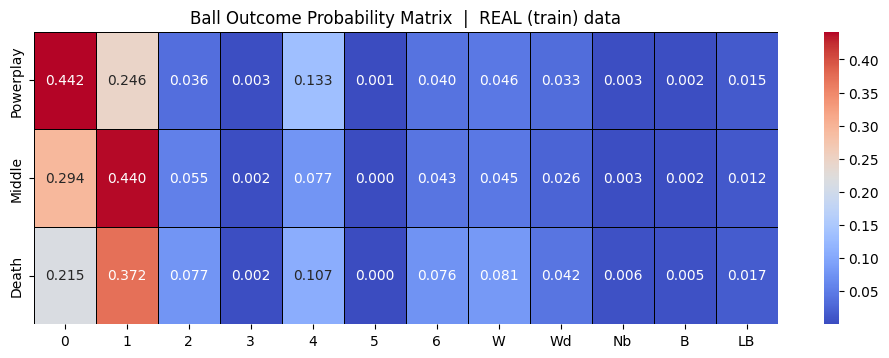

In [ ]:
plt.figure(figsize=(12, 3.8))
sns.heatmap(PHASE_PROBS, annot=True, fmt='.3f', cmap='coolwarm', xticklabels=OUTCOMES,
            yticklabels=PHASES, linewidths=0.5, linecolor='black')
plt.title('Ball Outcome Probability Matrix  |  ' + ('REAL (train) data' if REAL_LOADED else 'ASSUMED'))
plt.show()

## 3. Simulation Engine
Prottek *delivery* te ekta random number `u ~ U(0,1)` generate kore **inverse-CDF** method e outcome ber kora hoy (cumulative probability er sathe compare kore).

- `W` hole wicket porbe.
- `Wd`, `Nb` hole run jabe kintu `balls` barbe na (extra delivery).
- Innings sesh: 120 legal ball **ba** 10 wicket **ba** (chase hole) target pour hole.
- Code ta simple: ekta innings ek ek delivery kore `while` loop diye cholbe, thik real cricket er moto.

In [ ]:
def get_phase(balls):
    # legal ball count 0..119 -> phase 0 (Powerplay), 1 (Middle), 2 (Death)
    if balls < 36: return 0
    if balls < 90: return 1
    return 2

def adjust(p, strength):
    # strength > 1: batting strong (more 4/6, fewer wicket)
    q = p.copy()
    q[IDX['4']] *= strength
    q[IDX['6']] *= strength
    q[IDX['W']] /= strength
    return q / q.sum()           # normalise so sum = 1

def simulate_innings(n, strength, target=None, start_ball=0, start_runs=0, start_wkts=0):
    # n ta innings, ekta ekta kore simulate kore
    # cumulative probability (inverse-CDF er jonno), prottek phase er jonno
    cum = [list(np.cumsum(adjust(p, strength))) for p in PHASE_PROBS]
    for c in cum:
        c[-1] = 1.0

    all_runs, all_wkts, all_balls = [], [], []
    counts = np.zeros((3, K), dtype=int)            # outcome counts per phase (chi-square er jonno)

    for i in range(n):
        # target ekta number ba prottek match er jonno alada array hote pare
        tgt = target[i] if isinstance(target, np.ndarray) else target
        runs, wkts, balls = start_runs, start_wkts, start_ball   # balls = LEGAL ball count
        u = np.random.random(500)                   # ei innings er random number gulo
        d = 0                                       # koto tomo delivery hoise (u er index)

        while balls < 120 and wkts < 10:
            if tgt is not None and runs >= tgt:
                break                               # chase: target hoye gese
            ph  = get_phase(balls)
            out = bisect_left(cum[ph], u[d])        # inverse-CDF: kon outcome holo
            d  += 1

            runs += RUNS[out]
            if out == IDX['W']:
                wkts += 1
            if LEGAL[out]:                          # Wd/Nb e ball barbe na
                balls += 1
            counts[ph, out] += 1

        all_runs.append(runs); all_wkts.append(wkts); all_balls.append(balls)

    return np.array(all_runs), np.array(all_wkts), np.array(all_balls), counts

def play_matches(n, sA, sB):
    # Team A bats first, Team B chases
    runsA, wktsA, ballsA, cntA = simulate_innings(n, sA)
    target = runsA + 1
    runsB, wktsB, ballsB, cntB = simulate_innings(n, sB, target=target)
    winB = runsB >= target
    tie  = runsB == runsA
    winA = runsB < runsA
    return dict(runsA=runsA, runsB=runsB, winA=winA, winB=winB, tie=tie, cntA=cntA, cntB=cntB)

## 4. Monte Carlo: 10,000 Match
`TEAM_A` ar `TEAM_B` strength change kore different team compare korte parba (1.0 = average).

In [ ]:
N = 10000
TEAM_A, TEAM_B = 1.10, 1.00      # Team A bats first (stronger), Team B chases
NAME_A, NAME_B = 'Team A (Bat first)', 'Team B (Chase)'

res = play_matches(N, TEAM_A, TEAM_B)

pA, pB, pT = res['winA'].mean(), res['winB'].mean(), res['tie'].mean()
print(f'Average score  {NAME_A}: {res["runsA"].mean():.1f}  (std {res["runsA"].std():.1f})')
print(f'Win probability {NAME_A}: {pA:.3f}')
print(f'Win probability {NAME_B}: {pB:.3f}')
print(f'Tie probability: {pT:.3f}')

# Extras summary (Team A innings, per innings average)
cntA = res['cntA'].sum(axis=0) / N
print('\nPer innings average (Team A):')
for o in ['Wd', 'Nb', 'B', 'LB']:
    print(f'  {o:2s}: {cntA[IDX[o]]:.2f} ta delivery, {cntA[IDX[o]] * RUNS[IDX[o]]:.2f} run')
print(f'  Total delivery: {cntA.sum():.1f}  (legal ball = {cntA[LEGAL].sum():.1f})')
print(f'  Extras theke total run: {sum(cntA[IDX[o]] * RUNS[IDX[o]] for o in ["Wd","Nb","B","LB"]):.1f}')

Average score  Team A (Bat first): 161.9  (std 20.4)
Win probability Team A (Bat first): 0.608
Win probability Team B (Chase): 0.378
Tie probability: 0.014

Per innings average (Team A):
  Wd: 3.93 ta delivery, 3.93 run
  Nb: 0.47 ta delivery, 1.41 run
  B : 0.37 ta delivery, 0.74 run
  LB: 1.72 ta delivery, 1.72 run
  Total delivery: 123.4  (legal ball = 119.0)
  Extras theke total run: 7.8


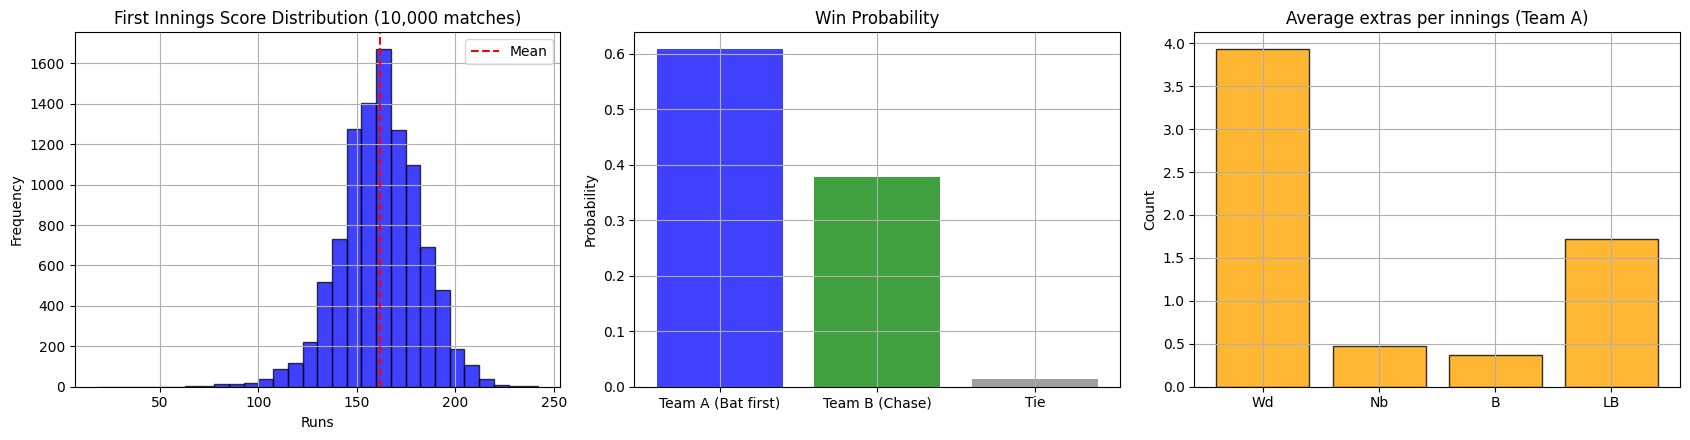

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

ax[0].hist(res['runsA'], bins=30, edgecolor='black', alpha=0.75, color='blue')
ax[0].axvline(res['runsA'].mean(), color='r', linestyle='--', label='Mean')
ax[0].set_title('First Innings Score Distribution (10,000 matches)')
ax[0].set_xlabel('Runs'); ax[0].set_ylabel('Frequency'); ax[0].legend(); ax[0].grid(True)

ax[1].bar([NAME_A, NAME_B, 'Tie'], [pA, pB, pT], color=['blue', 'green', 'gray'], alpha=0.75)
ax[1].set_title('Win Probability'); ax[1].set_ylabel('Probability'); ax[1].grid(True)

ex = ['Wd', 'Nb', 'B', 'LB']
ax[2].bar(ex, [cntA[IDX[o]] for o in ex], color='orange', alpha=0.8, edgecolor='black')
ax[2].set_title('Average extras per innings (Team A)'); ax[2].set_ylabel('Count'); ax[2].grid(True)

plt.tight_layout(); plt.show()

### 4.1 Convergence (Pi estimation er moto)
Match shonkha barle win probability stable hoy. 95% confidence band: $p \pm 1.96\sqrt{p(1-p)/n}$

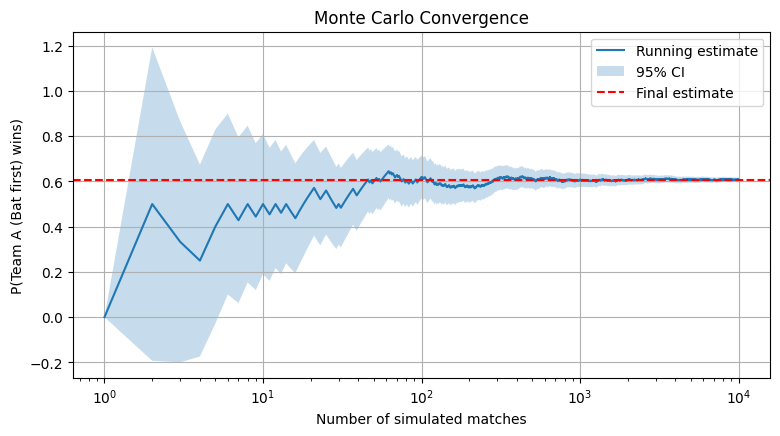

In [ ]:
x = res['winA'].astype(float)
n_axis = np.arange(1, N + 1)
running = np.cumsum(x) / n_axis
se = np.sqrt(running * (1 - running) / n_axis)

plt.figure(figsize=(9, 4.5))
plt.plot(n_axis, running, label='Running estimate')
plt.fill_between(n_axis, running - 1.96*se, running + 1.96*se, alpha=0.25, label='95% CI')
plt.axhline(running[-1], color='r', linestyle='--', label='Final estimate')
plt.xscale('log')
plt.xlabel('Number of simulated matches'); plt.ylabel(f'P({NAME_A} wins)')
plt.title('Monte Carlo Convergence'); plt.legend(); plt.grid(True); plt.show()

## 5. Chi-Square Goodness-of-Fit (Simulator Verification)
**H0:** simulated ball outcome frequency expected probability er sathe match kore (simulator thikmoto kaj korse).

> **Note:** Ekhane expected probability = simulator er input probability. Tai eta *verification* (code thik kaj korse kina) — *validation* (model real cricket er moto kina) na. Real validation Section 9 e.

Jei outcome er expected count 5 er niche (jemon `5` run), shegula ekshathe ekta "Other" bin e merge kora hoy (chi-square er standard rule).

Powerplay  chi2 =  13.93 | df = 11 | critical = 19.68 | p = 0.2368 | Fail to reject H0
Middle     chi2 =  19.38 | df = 11 | critical = 19.68 | p = 0.0546 | Fail to reject H0
Death      chi2 =   6.64 | df = 11 | critical = 19.68 | p = 0.8277 | Fail to reject H0


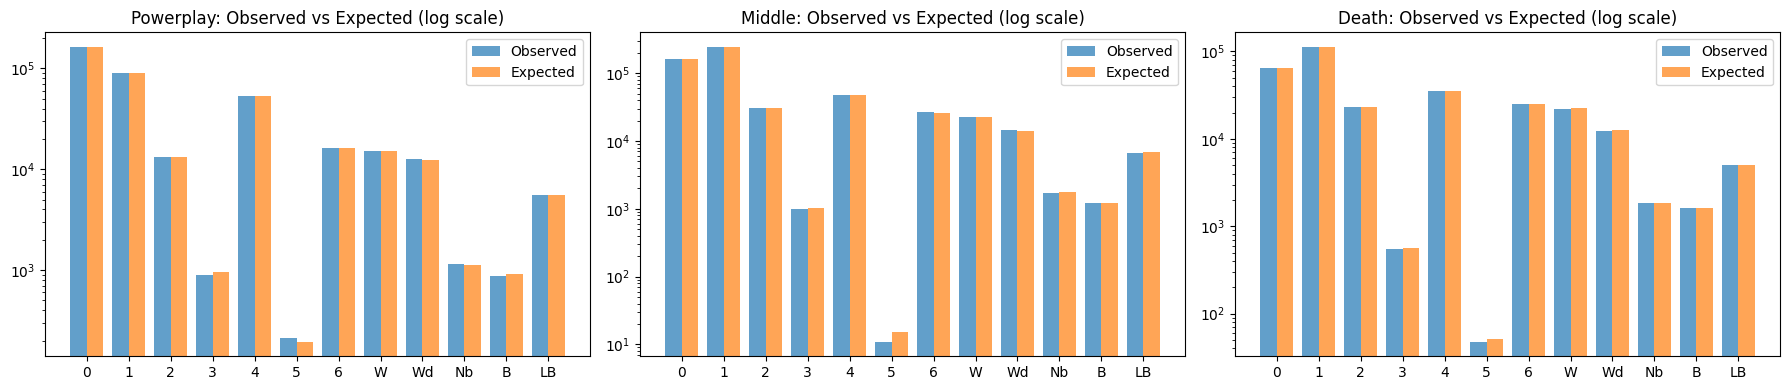

In [ ]:
alpha = 0.05

def chi_square_gof(observed, expected, alpha=0.05, min_exp=5):
    # expected count < 5 hole bin merge kore "Other" banano
    observed = np.asarray(observed, dtype=float)
    expected = np.asarray(expected, dtype=float)
    keep = expected >= min_exp
    obs = observed[keep]; exp = expected[keep]
    if (~keep).any() and expected[~keep].sum() > 0:
        obs = np.append(obs, observed[~keep].sum())
        exp = np.append(exp, expected[~keep].sum())
    exp = exp * obs.sum() / exp.sum()              # total match korano
    chi2, p = stats.chisquare(obs, exp)
    dof = len(obs) - 1
    crit = stats.chi2.ppf(1 - alpha, dof)
    return chi2, p, dof, crit

probsA = [adjust(p, TEAM_A) for p in PHASE_PROBS]
rows = []
for ph in range(3):
    observed = res['cntA'][ph]
    expected = probsA[ph] * observed.sum()
    chi2, p, dof, crit = chi_square_gof(observed, expected, alpha)
    decision = 'Reject H0' if chi2 > crit else 'Fail to reject H0'
    print(f'{PHASES[ph]:10s} chi2 = {chi2:6.2f} | df = {dof} | critical = {crit:.2f} | p = {p:.4f} | {decision}')
    rows.append((observed, expected))

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
for ph, (obs, exp) in enumerate(rows):
    idx = np.arange(K)
    ax[ph].bar(idx, obs, width=0.4, label='Observed', alpha=0.7)
    ax[ph].bar(idx + 0.4, exp, width=0.4, label='Expected', alpha=0.7)
    ax[ph].set_xticks(idx + 0.2); ax[ph].set_xticklabels(OUTCOMES)
    ax[ph].set_yscale('log')
    ax[ph].set_title(f'{PHASES[ph]}: Observed vs Expected (log scale)'); ax[ph].legend()
plt.tight_layout(); plt.show()

## 6. Two-Sample t-Test: Team A vs Team B Average Score
**H0:** duita team er average score same. **H1:** alada. Duita team i full 20 over bat kore (chase cut na kore) compare kora hoise.

Mean A = 161.11, Mean B = 153.25
t = 26.80, df = 19998, p = 1.787e-155
95% CI of mean difference: [7.29, 8.44]
Reject H0: team gulor average score alada.


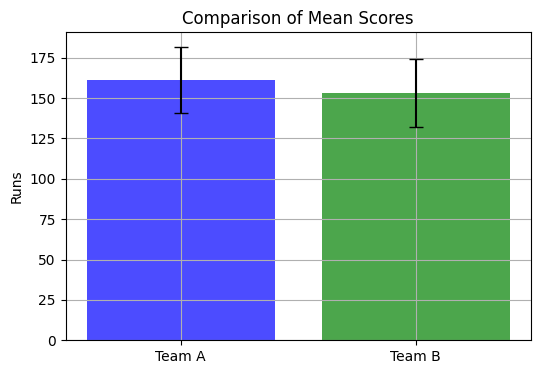

In [ ]:
scoresA, _, _, _ = simulate_innings(N, TEAM_A)
scoresB, _, _, _ = simulate_innings(N, TEAM_B)

t_stat, p_val = stats.ttest_ind(scoresA, scoresB, equal_var=True)
diff = scoresA.mean() - scoresB.mean()
sp = np.sqrt(((N-1)*scoresA.var(ddof=1) + (N-1)*scoresB.var(ddof=1)) / (2*N - 2))
se_diff = sp * np.sqrt(2 / N)
ci = stats.t.interval(0.95, 2*N - 2, loc=diff, scale=se_diff)

print(f'Mean A = {scoresA.mean():.2f}, Mean B = {scoresB.mean():.2f}')
print(f't = {t_stat:.2f}, df = {2*N-2}, p = {p_val:.4g}')
print(f'95% CI of mean difference: [{ci[0]:.2f}, {ci[1]:.2f}]')
print('Reject H0: team gulor average score alada.' if p_val < 0.05 else 'Fail to reject H0.')

plt.figure(figsize=(6, 4))
plt.bar(['Team A', 'Team B'], [scoresA.mean(), scoresB.mean()], color=['blue', 'green'], alpha=0.7)
plt.errorbar(['Team A', 'Team B'], [scoresA.mean(), scoresB.mean()],
             yerr=[scoresA.std(ddof=1), scoresB.std(ddof=1)], fmt='none', ecolor='k', capsize=5)
plt.title('Comparison of Mean Scores'); plt.ylabel('Runs'); plt.grid(True); plt.show()

## 7. KS Test and Normality Test
1. **Normality:** T20 score normal distribution follow kore kina? (`normaltest` + one-sample KS)
2. **Two-sample KS:** Team A ar Team B er score distribution ek i kina?

normaltest: stat = 407.88, p = 2.694e-89
One-sample KS vs Normal: D = 0.0282, p = 2.422e-07
Two-sample KS (A vs B): D = 0.1538, p = 1.47e-103


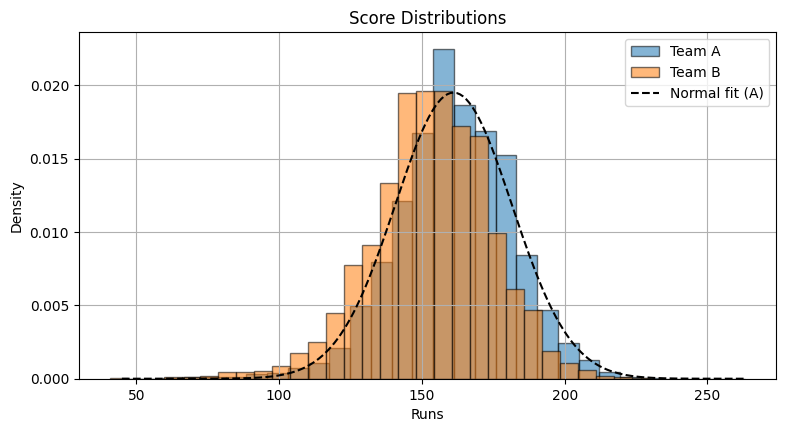

In [ ]:
# 1. Normality of Team A scores
k2, p_norm = stats.normaltest(scoresA)
z = (scoresA - scoresA.mean()) / scoresA.std(ddof=1)
ks_stat, p_ks = stats.kstest(z, 'norm')
print(f'normaltest: stat = {k2:.2f}, p = {p_norm:.4g}')
print(f'One-sample KS vs Normal: D = {ks_stat:.4f}, p = {p_ks:.4g}')

# 2. Team A vs Team B distribution
ks2, p_ks2 = stats.ks_2samp(scoresA, scoresB)
print(f'Two-sample KS (A vs B): D = {ks2:.4f}, p = {p_ks2:.4g}')

plt.figure(figsize=(9, 4.5))
plt.hist(scoresA, bins=30, alpha=0.55, label='Team A', density=True, edgecolor='black')
plt.hist(scoresB, bins=30, alpha=0.55, label='Team B', density=True, edgecolor='black')
xs = np.linspace(scoresA.min(), scoresA.max(), 200)
plt.plot(xs, stats.norm.pdf(xs, scoresA.mean(), scoresA.std(ddof=1)), 'k--', label='Normal fit (A)')
plt.xlabel('Runs'); plt.ylabel('Density'); plt.title('Score Distributions')
plt.legend(); plt.grid(True); plt.show()

## 8. Win Probability Heatmap (Matrix)
Team A (bat first) ar Team B (chase) er strength 0.8 theke 1.2 porjonto change kore **P(Team A wins)** matrix.

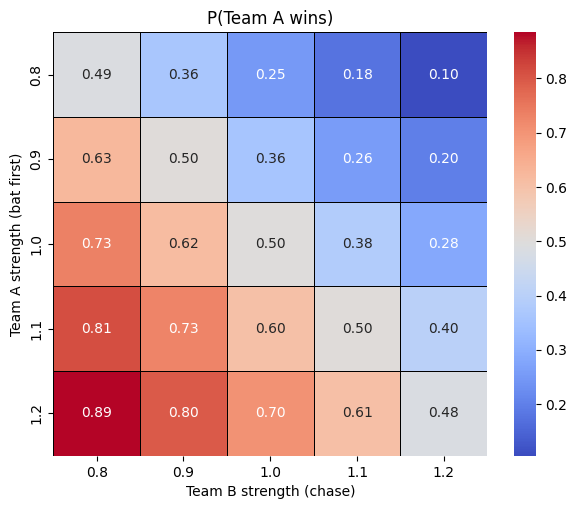

Equal teams: P(bat first wins) = 0.500, P(chasing wins) = 0.485


In [ ]:
strengths = [0.8, 0.9, 1.0, 1.1, 1.2]
M = np.zeros((len(strengths), len(strengths)))
for i, sa in enumerate(strengths):
    for j, sb in enumerate(strengths):
        M[i, j] = play_matches(3000, sa, sb)['winA'].mean()

plt.figure(figsize=(7, 5.5))
sns.heatmap(M, annot=True, fmt='.2f', cmap='coolwarm', xticklabels=strengths,
            yticklabels=strengths, linewidths=0.5, linecolor='black')
plt.xlabel('Team B strength (chase)'); plt.ylabel('Team A strength (bat first)')
plt.title('P(Team A wins)'); plt.show()

# Chase advantage when both teams are equal
eq = play_matches(N, 1.0, 1.0)
print(f'Equal teams: P(bat first wins) = {eq["winA"].mean():.3f}, P(chasing wins) = {eq["winB"].mean():.3f}')

## 9. Real Data Validation (shudhu CSV upload korle cholbe)
Model ta **train match** (70%) theke banano. Ekhon **test match** (30%, model ja kokhono dekhe nai) er sathe compare kora hocche:

- **(A) Chi-square test of homogeneity:** train data (jei data theke model bana) ar test data er ball outcome distribution same kina (phase onujayi, `chi2_contingency`). Jodi same hoy, model er probability test data te o khate.
- **(B) Score distribution:** real first-innings score vs simulated score (`strength = 1.0` = league average team). Welch t-test + two-sample KS.

> **Interpretation note:** real match e match-to-match variation (pitch, team, condition) thake, tai khub boro sample e chi-square reject hote pare — eta model er limitation, report e eta niye alochona korle valo. Test match sonkha kom hole (jemon 18 ta) first-innings score test er power kom, tai p-value boro ashle eta *proof na je model perfect*, shudhu *difference detect kora jay nai*.

(A) Chi-square (homogeneity): train vs test ball outcome distribution
  Powerplay  n_test =  10541 | chi2 =    6.72 | df = 11 | critical = 19.68 | p = 0.8214 | Fail to reject H0
  Middle     n_test =  15339 | chi2 =    9.05 | df = 11 | critical = 19.68 | p = 0.6176 | Fail to reject H0
  Death      n_test =   7267 | chi2 =   13.59 | df = 11 | critical = 19.68 | p = 0.2563 | Fail to reject H0

(B) First innings score: simulated vs real (test match)
  Real      : n = 141, mean = 156.4, std = 32.9
  Simulated : n = 10000, mean = 153.5, std = 20.9
  Welch t-test: t = -1.06, p = 0.2899
  Two-sample KS: D = 0.1965, p = 3.513e-05


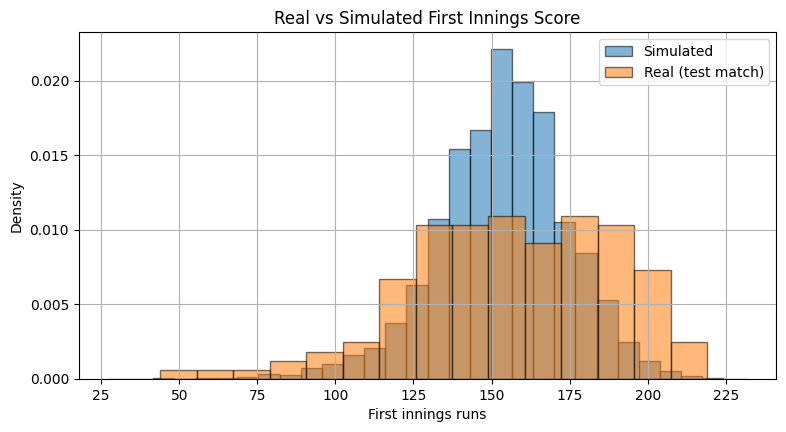

In [ ]:
if not REAL_LOADED:
    print('Real data upload kora hoy nai -> Section 9 skip. (Section 2 e CSV/ZIP upload kore abar run koro)')
else:
    # ---- (A) Chi-square test of homogeneity: train vs test ----
    print('(A) Chi-square (homogeneity): train vs test ball outcome distribution')
    for ph in range(3):
        # prottek outcome koto bar hoise (train ar test e)
        tr_c = train[train['phase'] == ph]['cat'].value_counts().reindex(OUTCOMES, fill_value=0).values
        te_c = test[test['phase']  == ph]['cat'].value_counts().reindex(OUTCOMES, fill_value=0).values

        # kom count er bin gulo "Other" e merge
        small = (tr_c + te_c) < 10
        table = np.array([tr_c, te_c])
        table = np.hstack([table[:, ~small], table[:, small].sum(axis=1, keepdims=True)])
        table = table[:, table.sum(axis=0) > 0]

        chi2, p, dof, _ = stats.chi2_contingency(table)
        crit = stats.chi2.ppf(1 - alpha, dof)
        d = 'Reject H0' if p < alpha else 'Fail to reject H0'
        print(f'  {PHASES[ph]:10s} n_test = {te_c.sum():6d} | chi2 = {chi2:7.2f} | df = {dof} | critical = {crit:.2f} | p = {p:.4f} | {d}')

    # ---- (B) Score distribution: real vs simulated ----
    real_scores = test[test['innings'] == 1].groupby('match_id')['total'].sum().values
    sim_scores, _, _, _ = simulate_innings(N, 1.0)

    t2, p2 = stats.ttest_ind(sim_scores, real_scores, equal_var=False)       # Welch
    ksr, pk = stats.ks_2samp(sim_scores, real_scores)
    print('\n(B) First innings score: simulated vs real (test match)')
    print(f'  Real      : n = {len(real_scores)}, mean = {real_scores.mean():.1f}, std = {real_scores.std(ddof=1):.1f}')
    print(f'  Simulated : n = {N}, mean = {sim_scores.mean():.1f}, std = {sim_scores.std(ddof=1):.1f}')
    print(f'  Welch t-test: t = {t2:.2f}, p = {p2:.4g}')
    print(f'  Two-sample KS: D = {ksr:.4f}, p = {pk:.4g}')

    plt.figure(figsize=(9, 4.5))
    plt.hist(sim_scores, bins=30, alpha=0.55, density=True, label='Simulated', edgecolor='black')
    plt.hist(real_scores, bins=15, alpha=0.55, density=True, label='Real (test match)', edgecolor='black')
    plt.xlabel('First innings runs'); plt.ylabel('Density')
    plt.title('Real vs Simulated First Innings Score'); plt.legend(); plt.grid(True); plt.show()

## 10. Live Win Probability (match chalar somoy)
Kono ekta match state (target, over, run, wicket) dile baki match simulate kore chasing team er win % ber kore.

Target = 161
Over  0: 0/0  -> win probability = 36.06%
Over  6: 50/1  -> win probability = 54.80%
Over 10: 80/2  -> win probability = 57.60%
Over 15: 115/4  -> win probability = 55.22%
Over 18: 140/6  -> win probability = 37.08%
Over 19: 150/7  -> win probability = 36.52%


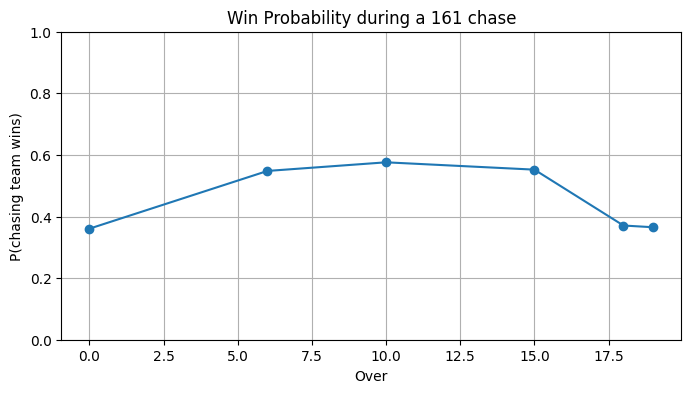

In [ ]:
def chase_win_prob(target_score, over, runs, wkts, strength=1.0, n=5000):
    # target_score = first innings total; chasing team needs target_score + 1
    need = target_score + 1
    r, w, b, _ = simulate_innings(n, strength, target=need, start_ball=over*6,
                                  start_runs=runs, start_wkts=wkts)
    return (r >= need).mean()

target_score = 160
states = [(0, 0, 0), (6, 50, 1), (10, 80, 2), (15, 115, 4), (18, 140, 6), (19, 150, 7)]
print(f'Target = {target_score+1}')
overs, probs = [], []
for ov, rn, wk in states:
    p = chase_win_prob(target_score, ov, rn, wk)
    overs.append(ov); probs.append(p)
    print(f'Over {ov:2d}: {rn}/{wk}  -> win probability = {p:.2%}')

plt.figure(figsize=(8, 4))
plt.plot(overs, probs, marker='o')
plt.xlabel('Over'); plt.ylabel('P(chasing team wins)'); plt.ylim(0, 1)
plt.title('Win Probability during a 161 chase'); plt.grid(True); plt.show()

## 11. Conclusion
- Monte Carlo diye 10,000 match simulate kore win probability estimate kora gese; match sonkha barle estimate stable hoy (convergence plot).
- Ball outcome e ekhon `0-6`, wicket ar extras (**wide, no-ball, bye, leg-bye**) ache. Wide/no-ball e legal ball count hoy na, tai innings e 120 er beshi delivery hoy.
- Chi-square (Section 5): simulated frequency input probability er sathe consistent -> simulator thik kaj korse (**verification**).
- t-test: strong team er average score significantly beshi (p < 0.05). Two-sample KS: duita team er score distribution alada.
- Normality test (normaltest + KS): T20 score exactly normal na — team all-out hole score kome jay (left tail), tai distribution skewed.
- Heatmap: team strength er difference e win probability kivabe change hoy dekhano hoise.
- **Real data validation (Section 9):** CSV upload korle model train/test split kore real match er sathe compare kora hoy (**validation**). Ekhane tomar actual result bosiye interpretation likho.

**Limitation:**
- Ball outcome gulo independent dhora hoise; bowler/batsman individual alada na, pressure/required run rate er effect nai (chase e batting aggression same).
- Extras er run fixed integer (real data theke average round kora); no-ball e bat theke extra run, free-hit, penalty run alada kore model kora hoyni.
- Team `strength` ekta single parameter (4, 6 ar wicket probability scale kore) — real team er stat theke estimate kora na.
- Pitch, weather, DLS, super over ignore kora hoise.

**Future work:** team-wise probability fit kora, individual player model, free-hit rule, required-run-rate based aggression, super over.